# Distributed gradient compression experiments

Compare FP32 all-reduce, FP32 all-gather, and QSGD with manual gradient synchronization. The Python module runs training. This notebook sets up paired experiments and analyzes their saved records.

## 1. Imports and environment

Open the notebook with a kernel that has this project's dependencies. If you have a saved result file, run the notebook with `RUN = None` to analyze it.

In [1]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0,2")

from dataclasses import replace
from itertools import product
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

PROJECT = Path.cwd()
if not (PROJECT / "distributed_training.py").is_file():
    candidates = [PROJECT / "gradient-compression", PROJECT / "cosc-6368-project/gradient-compression"]
    PROJECT = next(
        (path for path in candidates if (path / "distributed_training.py").is_file()), None
    )
    if PROJECT is None:
        raise FileNotFoundError("Open this notebook from the project directory or its repository root.")
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from distributed_training import (
    ExperimentConfig, compare_runtime, environment_info, load_results, load_step_metrics,
    run_experiment, run_experiments,
)

AVAILABLE_GPUS = torch.cuda.device_count() if torch.cuda.is_available() else 0
display({
    "visible_cuda_devices": AVAILABLE_GPUS,
    "cuda_devices": [
        {
            "index": index,
            "name": props.name,
            "memory_gib": round(props.total_memory / 2**30, 2),
            "compute_capability": f"{props.major}.{props.minor}",
        }
        for index in range(AVAILABLE_GPUS)
        for props in [torch.cuda.get_device_properties(index)]
    ],
    "environment": environment_info(),
})

{'visible_cuda_devices': 2,
 'cuda_devices': [{'index': 0,
   'name': 'NVIDIA RTX 6000 Ada Generation',
   'memory_gib': 47.37,
   'compute_capability': '8.9'},
  {'index': 1,
   'name': 'NVIDIA RTX 6000 Ada Generation',
   'memory_gib': 47.37,
   'compute_capability': '8.9'}],
 'environment': {'hardware': {'hostname': 'cs-czhang59-0000385',
   'platform': 'Linux-5.15.0-176-generic-x86_64-with-glibc2.35',
   'cpu': 'x86_64',
   'logical_cpus': 128,
   'visible_gpus': [{'index': 0,
     'name': 'NVIDIA RTX 6000 Ada Generation',
     'memory_bytes': 50865307648,
     'compute_capability': [8, 9],
     'uuid': '2269e4ec-3027-b081-de89-2e4c2a5fc7bb'},
    {'index': 1,
     'name': 'NVIDIA RTX 6000 Ada Generation',
     'memory_bytes': 50865307648,
     'compute_capability': [8, 9],
     'uuid': '7d9c8c3b-9611-be0b-ff96-d19518c59233'}],
   'topology': '\x1bGPU0\tGPU1\tGPU2\tGPU3\tGPU4\tGPU5\tGPU6\tGPU7\tCPU Affinity\tNUMA Affinity\tGPU NUMA ID\x1b\nGPU0\t X \tNODE\tNODE\tNODE\tSYS\tSYS\tSYS

## 2. Experiment configuration

The initial suite uses the first seed and capped datasets and budgets. The expanded suite crosses bit widths, bucket sizes, normalizations, encodings, and seeds. Enable `EXPANDED_DIAGNOSTICS` for a sweep of reconstruction errors and detailed timings. Choose `evaluate_test=True` for final runs with settings chosen on validation data. Put any additional `ExperimentConfig` settings in `EXTRA_CONFIG`.

In [ ]:
RUN = "expanded"  # None, "single", "initial", "diagnostic", "expanded", or "scaling"
OUTPUT_FILE = Path("~/data/cosc-6368-project-results/experiment_results.json").expanduser()
DATA_DIR= Path("~/data/cosc-6368-project-datasets").expanduser()
SUMMARY_CSV = None  # e.g. PROJECT / "results/summary.csv"
ANALYZE_IDS = None  # e.g. {"<experiment-id>"} to select runs
ORDER_SEED = None  # set an integer to shuffle execution order reproducibly

NUM_GPUS = min(2, AVAILABLE_GPUS)
GPU_IDS = None  # if set, length must match NUM_GPUS
CPU_PROCESSES = 2
LOCAL_BATCH_SIZE = 128
GLOBAL_BATCH_SIZE = None
EPOCHS = 10
MAX_STEPS = None
LEARNING_RATE = 0.01
HIDDEN_DIMS = (1024, 512, 256)
EMNIST_SPLIT = "byclass"
QUANTIZATION_BITS = [4]
QUANTIZATION_BUCKET_SIZES = [512]
NORMALIZATION_METHODS = ["l2"]
ENCODINGS = ["packed"]
SEEDS = [42]
REPETITIONS = 1
WARMUP_STEPS = 0
TARGET_VALIDATION_LOSS = None
TARGET_VALIDATION_ACCURACY = None
SCALING_GPU_COUNTS = [count for count in (1, 2, 4, 8) if count <= AVAILABLE_GPUS]
SCALING_GLOBAL_BATCH_SIZE = 256
ERROR_LOG_SCALE = False
EXPANDED_DIAGNOSTICS = False
SHOW_LAYER_ERRORS = False

EXTRA_CONFIG = {
    "validation_fraction": 0.1,
    "data_dir": str(DATA_DIR),
    "communication_bucket_bytes": 4 * 2**20,
    "evaluate_test": False,
    "step_metrics": False,
}
STARTER_QSGD = {
    "synchronization": "compressed_allgather",
    "compression": "qsgd",
    "quantization_bits": 4,
    "quantization_bucket_size": 512,
    "normalization": "l2",
    "encoding": "packed",
}
SINGLE_OVERRIDES = STARTER_QSGD

base_options = {
    "num_gpus": NUM_GPUS,
    "gpu_ids": GPU_IDS,
    "cpu_processes": CPU_PROCESSES if NUM_GPUS == 0 else 1,
    "local_batch_size": LOCAL_BATCH_SIZE,
    "global_batch_size": GLOBAL_BATCH_SIZE,
    "batch_scaling": "fixed_global" if GLOBAL_BATCH_SIZE is not None else "fixed_local",
    "epochs": EPOCHS,
    "max_steps": MAX_STEPS,
    "learning_rate": LEARNING_RATE,
    "hidden_dims": HIDDEN_DIMS,
    "emnist_split": EMNIST_SPLIT,
    "seed": SEEDS[0],
    "repetitions": REPETITIONS,
    "warmup_steps": WARMUP_STEPS,
    "target_validation_loss": TARGET_VALIDATION_LOSS,
    "target_validation_accuracy": TARGET_VALIDATION_ACCURACY,
    "output_file": str(OUTPUT_FILE),
}
base = ExperimentConfig(**(base_options | EXTRA_CONFIG))

## 3. Launch or reload experiments

Each paired condition uses both FP32 baselines with the same model, seed, dataset split, batch size, and stopping rule. Diagnostic runs collect error and detailed phase timings on a separate pass. For scaling runs, the fixed-global series holds the total batch size constant and the fixed-local series increases it with the GPU count.

In [16]:
BASELINES = ("fp32_allreduce", "fp32_allgather")

def paired_suite(config, variants):
    return [
        *(replace(config, synchronization=method) for method in BASELINES),
        *(replace(config, **variant) for variant in variants),
    ]


def capped(value, cap):
    return min(value, cap) if value is not None else cap


def initial_base(config):
    return replace(
        config,
        epochs=capped(config.epochs, 2),
        max_steps=capped(config.max_steps, 12),
        train_size_limit=capped(config.train_size_limit, 8192),
        validation_size_limit=capped(config.validation_size_limit, 1024),
        test_size_limit=capped(config.test_size_limit, 1024),
        repetitions=1,
    )


def diagnostic_config(config):
    return replace(
        config, mode="diagnostic", gradient_error="both", detailed_timing=True,
        step_metrics=True, per_layer_error=True,
    )


if RUN == "single":
    display(run_experiment(replace(base, **SINGLE_OVERRIDES))["experiment_id"])
elif RUN in {"initial", "diagnostic"}:
    starter = initial_base(base)
    if RUN == "diagnostic":
        starter = diagnostic_config(starter)
    variants = [STARTER_QSGD]
    if RUN == "diagnostic":
        variants.append(STARTER_QSGD | {"normalization": "max"})
    planned = paired_suite(starter, variants)
    display([row["experiment_id"] for row in run_experiments(planned, order_seed=ORDER_SEED)])
elif RUN == "expanded":
    variants = [
        STARTER_QSGD | {
            "quantization_bits": bits, "quantization_levels": None,
            "quantization_bucket_size": bucket, "normalization": norm, "encoding": encoding,
        }
        for bits, bucket, norm, encoding in product(
            QUANTIZATION_BITS, QUANTIZATION_BUCKET_SIZES, NORMALIZATION_METHODS, ENCODINGS
        )
    ]
    expanded = diagnostic_config(base) if EXPANDED_DIAGNOSTICS else base
    planned = [config for seed in SEEDS for config in paired_suite(replace(expanded, seed=seed), variants)]
    display([row["experiment_id"] for row in run_experiments(planned, order_seed=ORDER_SEED)])
elif RUN == "scaling":
    if not SCALING_GPU_COUNTS or any(count < 1 or count > AVAILABLE_GPUS for count in SCALING_GPU_COUNTS):
        raise ValueError("Choose scaling GPU counts from the visible CUDA devices.")
    if any(SCALING_GLOBAL_BATCH_SIZE % count for count in SCALING_GPU_COUNTS):
        raise ValueError("SCALING_GLOBAL_BATCH_SIZE must divide evenly across each GPU count.")
    planned = []
    for count, scaling, seed in product(SCALING_GPU_COUNTS, ("fixed_local", "fixed_global"), SEEDS):
        condition = replace(
            base, device="cuda", num_gpus=count, gpu_ids=None, cpu_processes=1, seed=seed,
            batch_scaling=scaling,
            global_batch_size=SCALING_GLOBAL_BATCH_SIZE if scaling == "fixed_global" else None,
        )
        planned.extend(paired_suite(condition, [STARTER_QSGD]))
    display([row["experiment_id"] for row in run_experiments(planned, order_seed=ORDER_SEED)])
elif RUN is not None:
    raise ValueError(f"Unknown launch choice {RUN!r}.")

records = load_results(OUTPUT_FILE) if OUTPUT_FILE.exists() else []
if ANALYZE_IDS is not None:
    records = [row for row in records if row["experiment_id"] in ANALYZE_IDS]
completed = [row for row in records if row.get("status") == "completed"]
print(f"Loaded {len(records)} runs, {len(completed)} completed, from {OUTPUT_FILE}.")

'9ab7da8dbcff415b88d6315de309494e'

Loaded 1 runs, 1 completed, from /home/nicholas/data/cosc-6368-project-results/experiment_results.json.


## 4. Runtime comparisons

Benchmark charts use training-only wall time and keep both baseline comparisons. The detailed diagnostic charts appear separately. The phase stack excludes the synchronization envelope and the Elias subphases because their durations overlap the displayed component times. Speedup divides the matched baseline runtime by the QSGD runtime. Values below one indicate a slowdown. Check the paired step counts and target outcomes before comparing runs that stopped at different points.

In [17]:
COMPRESSION_FIELDS = {
    "synchronization", "compression", "normalization", "quantization_bits",
    "quantization_levels", "quantization_bucket_size", "encoding",
    "min_compression_elements", "compression_seed",
}
OUTPUT_FIELDS = {"output_file", "save_checkpoint", "step_metrics_format", "repetitions"}


def nested(record, *keys):
    for key in keys:
        if not isinstance(record, dict):
            return None
        record = record.get(key)
    return record


def signature(record, excluded, *, include_repetition=False, across_gpu_counts=False):
    config = record.get("configuration", {})
    hardware = record.get("hardware", {}).copy()
    if across_gpu_counts:
        for key in ("selected_gpu_ids", "world_size"):
            hardware.pop(key, None)
    identity = {
        "configuration": {key: value for key, value in config.items() if key not in excluded},
        "hardware": hardware,
        "software_environment": record.get("software_environment", {}),
    }
    if include_repetition:
        identity["repetition"] = record.get("repetition")
    return json.dumps(identity, sort_keys=True)


def run_label(record):
    config = record.get("configuration", {})
    method = config.get("synchronization", "unknown")
    if method == "compressed_allgather":
        method = config.get("compression", "qsgd")
        if method == "qsgd":
            bucket = config.get("quantization_bucket_size")
            method = f"QSGD {config.get('normalization')} {config.get('quantization_bits')}-bit"
            method += f" / {bucket if bucket is not None else 'whole'} / {config.get('encoding')}"
    return f"{method} · {record['experiment_id'][-8:]}"


def summary_row(record):
    config = record.get("configuration", {})
    compressed = config.get("synchronization") == "compressed_allgather"
    qsgd = compressed and config.get("compression") == "qsgd"
    row = {
        "experiment_id": record["experiment_id"],
        "label": run_label(record),
        "status": record.get("status"),
        "stop_reason": nested(record, "summary", "stop_reason"),
        "error": record.get("error"),
        "mode": config.get("mode"),
        "synchronization": config.get("synchronization"),
        "compression": config.get("compression") if compressed else "fp32",
        "normalization": config.get("normalization") if qsgd else None,
        "quantization_bits": config.get("quantization_bits") if qsgd else None,
        "quantization_levels": config.get("quantization_levels") if qsgd else None,
        "quantization_bucket_size": config.get("quantization_bucket_size") if qsgd else None,
        "encoding": config.get("encoding") if qsgd else None,
        "num_gpus": config.get("num_gpus"),
        "batch_scaling": config.get("batch_scaling"),
        "seed": config.get("seed"),
        "repetition": record.get("repetition"),
        "target_validation_loss": config.get("target_validation_loss"),
        "target_validation_accuracy": config.get("target_validation_accuracy"),
        "total_parameters": nested(record, "model_metadata", "total_parameters"),
        "trial_group": signature(record, OUTPUT_FIELDS | {"seed"}),
    }
    for name in (
        "total_runtime", "training_runtime", "validation_runtime", "mean_epoch_runtime",
        "mean_step_runtime", "synchronization_runtime", "compression_runtime",
        "decompression_runtime", "collective_runtime", "samples_per_second",
        "final_train_loss", "final_train_accuracy", "final_validation_loss",
        "final_validation_accuracy", "final_test_loss", "final_test_accuracy",
        "optimizer_steps", "global_batches", "samples_processed", "epochs_completed",
        "local_batch_size", "global_batch_size", "world_size", "num_gpus",
    ):
        value = nested(record, "summary", name)
        if value is not None or name not in row:
            row[name] = value
    for name in (
        "rounds", "collective_calls", "diagnostic_collective_calls", "compression_ratio",
        "logical_bytes", "estimated_aggregate_bytes", "encoded_total_bytes",
    ):
        row[name] = nested(record, "communication_metrics", name)
    for group, metric in product(("local", "aggregated"), ("mse", "rmse", "max_error", "mae")):
        row[f"{group}_{metric}"] = nested(record, "gradient_error_metrics", group, metric)
    for name in (
        "target_reached", "time_to_target", "epoch_to_target", "step_to_target",
        "global_batches_to_target", "synchronization_rounds_to_target", "collective_calls_to_target",
        "communication_bytes_to_target",
    ):
        row[name] = nested(record, "convergence_metrics", name)
    return row


def history_row(record, item):
    row = {
        **{key: item.get(key) for key in (
            "epoch", "step", "samples_processed", "train_loss", "train_accuracy", "validation_loss",
            "validation_accuracy", "epoch_runtime", "step_runtime", "cumulative_runtime",
            "cumulative_training_time", "learning_rate",
        )},
        "experiment_id": record["experiment_id"],
        "label": run_label(record),
        "mode": nested(record, "configuration", "mode"),
    }
    for group, metric in product(("local", "aggregated"), ("mse", "rmse", "max_error")):
        row[f"{group}_{metric}"] = nested(item, "gradient_errors", group, metric)
    return row


def frame(rows):
    table = pd.DataFrame(rows)
    if table.empty:
        return table
    return table.convert_dtypes()


summary = frame(summary_row(record) for record in records)
epoch_history = frame(history_row(record, item) for record in completed for item in record["epoch_metrics"])
step_history = frame(
    history_row(record, item) for record in completed for item in load_step_metrics(record, OUTPUT_FILE)
)


def select(table, column, value):
    if column in table:
        return table.loc[table[column].eq(value).fillna(False)]
    return table.iloc[0:0]


def observations(table, *columns):
    if not set(columns).issubset(table.columns):
        return table.iloc[0:0]
    return table.dropna(subset=list(columns))


def numeric(series):
    return pd.to_numeric(series).to_numpy(dtype=float, na_value=np.nan)


def subplots(specs, width=2):
    columns = min(width, len(specs))
    fig, axes = plt.subplots(
        (len(specs) + columns - 1) // columns, columns,
        figsize=(6.4 * columns, 3.8 * ((len(specs) + columns - 1) // columns)),
        squeeze=False, layout="constrained",
    )
    for ax in axes.flat[len(specs):]:
        ax.set_visible(False)
    return fig, axes.flat


def histories(table, x, x_label, specs, *, log=False):
    available = [(key, title) for key, title in specs if not observations(table, x, key).empty]
    if not available:
        return
    fig, axes = subplots(available)
    for ax, (key, title) in zip(axes, available):
        values = observations(table, x, key)
        if log:
            values = values.loc[values[key] > 0]
        for label, group in values.groupby("label", sort=False):
            group = group.sort_values(x)
            ax.plot(numeric(group[x]), numeric(group[key]), marker=".", label=label)
        ax.set(xlabel=x_label, ylabel=title)
        if log and not values.empty:
            ax.set_yscale("log")
        if 0 < values["label"].nunique() <= 10:
            ax.legend(fontsize="small")
    plt.show()
    plt.close(fig)


def run_bars(table, specs, *, label="label"):
    available = [(key, title) for key, title in specs if not observations(table, key).empty]
    if not available:
        return
    fig, axes = subplots(available)
    for ax, (key, title) in zip(axes, available):
        values = observations(table, key)
        y = np.arange(len(values))
        ax.barh(y, numeric(values[key]))
        ax.set_yticks(y, labels=values[label], fontsize="small")
        ax.set_xlabel(title)
        ax.invert_yaxis()
    fig.set_figheight(max(fig.get_figheight(), (len(table) * 0.23 + 1.5) * ((len(available) + 1) // 2)))
    plt.show()
    plt.close(fig)


def scatters(table, specs, *, group=None, log_y=False):
    table = table.copy()
    if "quantization_bucket_size" in table:
        table["quantization_bucket_label"] = table["quantization_bucket_size"].map(
            lambda size: str(int(size)) if pd.notna(size) else "Whole buffer"
        )
        specs = [
            ("quantization_bucket_label" if x == "quantization_bucket_size" else x, x_label, y, y_label)
            for x, x_label, y, y_label in specs
        ]
    available = [
        (x, x_label, y, y_label) for x, x_label, y, y_label in specs
        if not observations(table, x, y).empty
    ]
    if not available:
        return
    fig, axes = subplots(available)
    for ax, (x, x_label, y, y_label) in zip(axes, available):
        values = observations(table, x, y)
        if log_y:
            values = values.loc[values[y] > 0]
        grouped = values.groupby(group, dropna=False, sort=False) if group else [(None, values)]
        if x == "quantization_bucket_label":
            ordered = sorted(values[x].unique(), key=lambda label: int(label) if label.isdigit() else np.inf)
            positions = {label: index for index, label in enumerate(ordered)}
            ax.set_xticks(list(positions.values()), labels=ordered)
        for label, rows in grouped:
            x_values = rows[x].map(positions) if x == "quantization_bucket_label" else numeric(rows[x])
            ax.scatter(x_values, numeric(rows[y]), label=label, alpha=0.75)
        ax.set(xlabel=x_label, ylabel=y_label)
        if log_y and not values.empty:
            ax.set_yscale("log")
        if group and not values.empty:
            ax.legend(fontsize="small")
    plt.show()
    plt.close(fig)


pair_index = {}
for record in completed:
    method = nested(record, "configuration", "synchronization")
    if method in BASELINES:
        key = signature(record, OUTPUT_FIELDS | COMPRESSION_FIELDS, include_repetition=True)
        pair_index.setdefault((key, method), []).append(record)

matched = []
for record in completed:
    if nested(record, "configuration", "synchronization") != "compressed_allgather":
        continue
    key = signature(record, OUTPUT_FIELDS | COMPRESSION_FIELDS, include_repetition=True)
    for method in BASELINES:
        references = pair_index.get((key, method), [])
        if references:
            matched.append((record, method, references))


def performance_pairs():
    for record, method, references in matched:
        if nested(record, "configuration", "mode") != "benchmark":
            continue
        references = [
            candidate for candidate in references
            if (value := nested(candidate, "summary", "training_runtime")) is not None and value > 0
        ]
        baseline_runtimes = [nested(candidate, "summary", "training_runtime") for candidate in references]
        runtime = nested(record, "summary", "training_runtime")
        if not baseline_runtimes or runtime is None or runtime <= 0:
            continue
        median = float(np.median(baseline_runtimes))
        baseline_steps = [
            step for candidate in references
            if (step := nested(candidate, "summary", "optimizer_steps")) is not None
        ]
        baseline_outcomes = [nested(candidate, "convergence_metrics", "target_reached") for candidate in references]
        row = summary_row(record)
        scaling_config = BASE_OPTIONS_FOR_SCALING | (
            {"local_batch_size"} if row["batch_scaling"] == "fixed_global" else {"global_batch_size"}
        )
        yield {
            "experiment_id": record["experiment_id"], "label": run_label(record),
            "baseline_method": method, "reference_count": len(baseline_runtimes),
            "baseline_training_runtime": median, "training_runtime": runtime,
            "compressed_steps": row["optimizer_steps"],
            "baseline_steps_min": min(baseline_steps, default=None),
            "baseline_steps_max": max(baseline_steps, default=None),
            "target_reached": row["target_reached"],
            "baseline_targets_reached": sum(outcome is True for outcome in baseline_outcomes)
                                        if any(outcome is not None for outcome in baseline_outcomes) else None,
            "num_gpus": row["num_gpus"], "batch_scaling": row["batch_scaling"],
            "scaling_group": signature(record, scaling_config, across_gpu_counts=True),
            **compare_runtime(median, runtime),
        }


BASE_OPTIONS_FOR_SCALING = OUTPUT_FIELDS | {"seed", "num_gpus", "gpu_ids"}
pairs = frame(performance_pairs())
succeeded = select(summary, "status", "completed")
bench_summary = select(succeeded, "mode", "benchmark")
diag_summary = select(succeeded, "mode", "diagnostic")
bench_epochs, diag_epochs = (select(epoch_history, "mode", mode) for mode in ("benchmark", "diagnostic"))
bench_steps, diag_steps = (select(step_history, "mode", mode) for mode in ("benchmark", "diagnostic"))

,label,training_runtime,synchronization_runtime,logical_bytes,estimated_aggregate_bytes,samples_per_second
0,QSGD l2 4-bit / 512 / packed · e309494e,258.416482,None,36769635980,36769635980,24300.617133


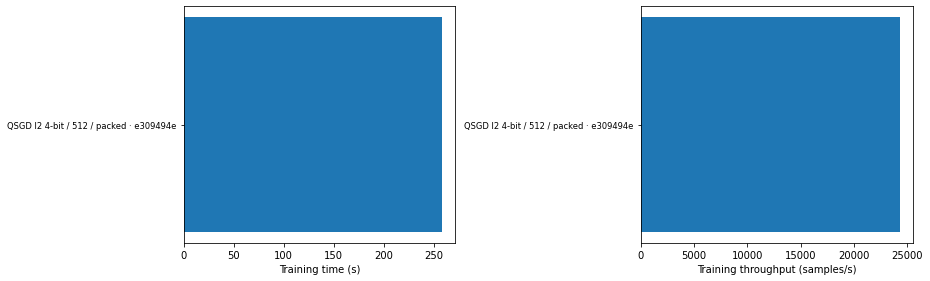

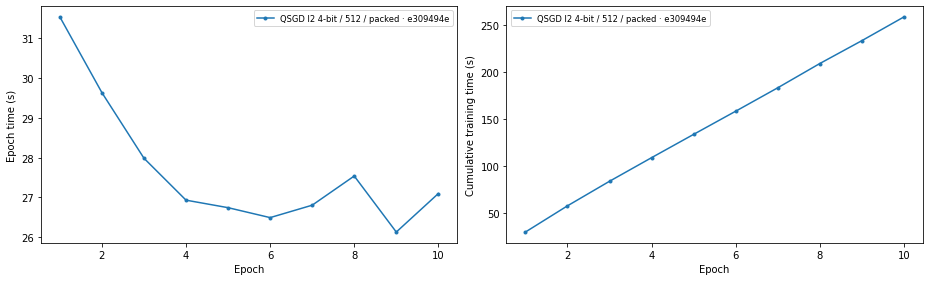

In [18]:
def phase_breakdown(mode):
    names = (
        "data_loading", "host_to_device", "forward", "backward", "prepare_gradients",
        "compression", "collective", "decompression", "aggregation", "restore_gradients",
        "optimizer", "diagnostic_collective", "diagnostic_error",
    )
    rows = [
        {"label": run_label(record), **{
            name: nested(record, "summary", "timing", name) for name in names
        }}
        for record in completed if nested(record, "configuration", "mode") == mode
    ]
    timings = pd.DataFrame(rows).dropna(axis=1, how="all")
    if timings.shape[1] > 1:
        timings = timings.set_index("label")
        ax = timings.plot.barh(stacked=True, figsize=(10, max(3.2, len(timings) * 0.34 + 1.5)))
        ax.set(xlabel="Recorded phase time (s)", ylabel="")
        ax.legend(title="Phase", bbox_to_anchor=(1.03, 1))
        plt.show()
        plt.close(ax.figure)


def scaling_plot(pairs):
    values = observations(pairs, "num_gpus", "speedup")
    if values.empty:
        return
    values = values.loc[values["num_gpus"] > 0]
    scaling_modes = list(values["batch_scaling"].dropna().unique())
    if not scaling_modes:
        return
    fig, axes = subplots(scaling_modes)
    for ax, scaling in zip(axes, scaling_modes):
        conditions = values.loc[values["batch_scaling"] == scaling]
        for index, ((method, _), runs) in enumerate(
            conditions.groupby(["baseline_method", "scaling_group"], sort=False), 1
        ):
            by_gpu = runs.groupby("num_gpus")["speedup"].agg(["mean", "std"])
            ax.errorbar(
                numeric(by_gpu.index.to_series()), numeric(by_gpu["mean"]),
                yerr=numeric(by_gpu["std"].fillna(0)), marker="o", label=f"{method} · {index}",
            )
        ax.axhline(1, color="gray", linewidth=1)
        ax.set(title=scaling.replace("_", " "), xlabel="GPU count", ylabel="Matched speedup (×)")
        if len(ax.lines) <= 11:
            ax.legend(fontsize="small")
    plt.show()
    plt.close(fig)


runtime_specs = [
    ("training_runtime", "Training time (s)"),
    ("samples_per_second", "Training throughput (samples/s)"),
    ("synchronization_runtime", "Gradient synchronization (s)"),
    ("collective_runtime", "Collective communication (s)"),
    ("compression_runtime", "Compression (s)"),
    ("decompression_runtime", "Decompression (s)"),
]
if not bench_summary.empty:
    display(bench_summary[[
        "label", "training_runtime", "synchronization_runtime", "logical_bytes",
        "estimated_aggregate_bytes", "samples_per_second",
    ]])
    run_bars(bench_summary, runtime_specs)
    histories(bench_epochs, "epoch", "Epoch", [
        ("epoch_runtime", "Epoch time (s)"), ("cumulative_training_time", "Cumulative training time (s)"),
    ])
    histories(bench_steps, "step", "Optimizer step", [("step_runtime", "Step time (s)")])
    phase_breakdown("benchmark")
if not pairs.empty:
    display(pairs.drop(columns="scaling_group"))
    scaling_plot(pairs)

### Diagnostic timing

These runs record extra operations, such as full-precision reference collectives. Read these timings as measurements of individual phases.

In [19]:
if not diag_summary.empty:
    run_bars(diag_summary, runtime_specs)
    histories(diag_epochs, "epoch", "Epoch", [
        ("epoch_runtime", "Diagnostic epoch time (s)"),
        ("cumulative_training_time", "Cumulative diagnostic training time (s)"),
    ])
    histories(diag_steps, "step", "Optimizer step", [("step_runtime", "Diagnostic step time (s)")])
    phase_breakdown("diagnostic")

## 5. Loss and accuracy

Epoch and step charts show optimization progress. The elapsed-time charts use the run's cumulative time, including intervening validation. Training loss and accuracy are measured on the batches processed during optimization. Final test accuracy is available for runs that enabled held-out evaluation.

'Benchmark runs'

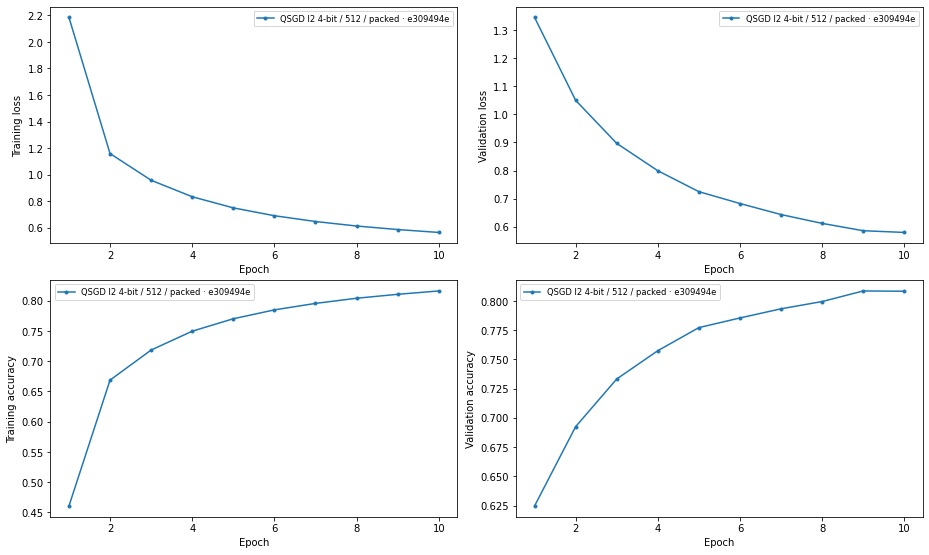

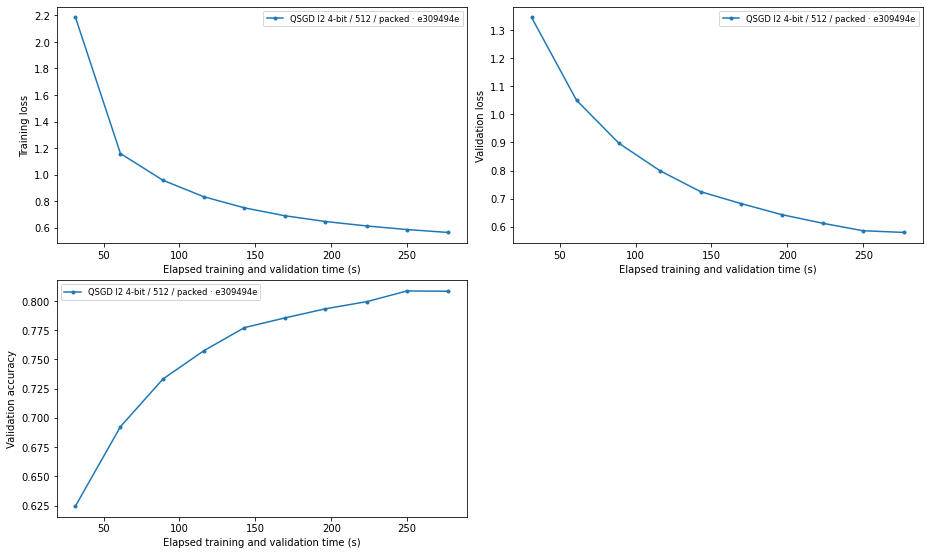

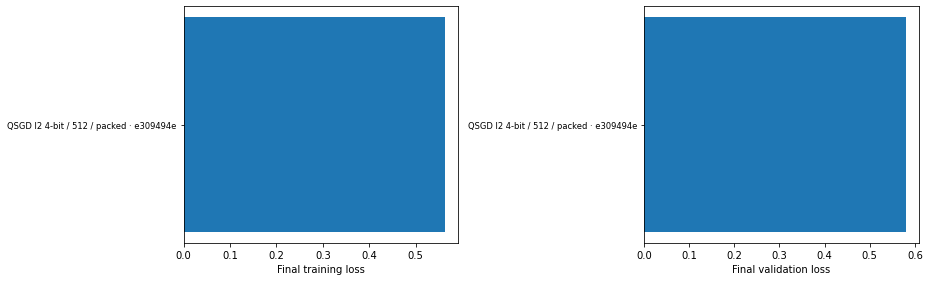

In [20]:
quality_specs = [
    ("train_loss", "Training loss"), ("validation_loss", "Validation loss"),
    ("train_accuracy", "Training accuracy"), ("validation_accuracy", "Validation accuracy"),
]
for mode in ("benchmark", "diagnostic"):
    epochs = select(epoch_history, "mode", mode)
    steps = select(step_history, "mode", mode)
    runs = select(succeeded, "mode", mode)
    if runs.empty:
        continue
    display(f"{mode.title()} runs")
    histories(epochs, "epoch", "Epoch", quality_specs)
    histories(steps, "step", "Optimizer step", [("train_loss", "Training loss")])
    histories(epochs, "cumulative_runtime", "Elapsed training and validation time (s)", [
        ("train_loss", "Training loss"), ("validation_loss", "Validation loss"),
        ("validation_accuracy", "Validation accuracy"),
    ])
    run_bars(runs, [
        ("final_train_loss", "Final training loss"),
        ("final_validation_loss", "Final validation loss"),
        ("final_test_accuracy", "Final test accuracy"),
    ])

## 6. Convergence targets

A target is reached at the first qualifying validation evaluation. The table lists its outcome for every targeted run. Charts omit time and communication values for runs whose target remained unreached.

In [21]:
if not succeeded.empty:
    targeted = succeeded.loc[
        succeeded[["target_validation_loss", "target_validation_accuracy"]].notna().any(axis=1)
    ].copy()
    if targeted.empty:
        display("No validation targets are configured in the completed runs.")
    else:
        targeted["outcome"] = targeted["target_reached"].map(
            {True: "Reached", False: "Unreached"}
        ).fillna("Unavailable")
        target_specs = [
            ("epoch_to_target", "Epoch to target"),
            ("global_batches_to_target", "Global mini-batches to target"),
            ("synchronization_rounds_to_target", "Gradient synchronization rounds to target"),
            ("collective_calls_to_target", "Gradient collective calls to target"),
            ("time_to_target", "Elapsed time to target (s)"),
            ("communication_bytes_to_target", "Estimated aggregate gradient traffic to target (bytes)"),
        ]
        display(targeted[[
            "label", "mode", "target_validation_loss", "target_validation_accuracy", "outcome",
            *(key for key, _ in target_specs),
        ]])
        for (mode, loss, accuracy), runs in targeted.groupby(
            ["mode", "target_validation_loss", "target_validation_accuracy"], dropna=False, sort=False
        ):
            criteria = ", ".join(
                name for valid, name in (
                    (pd.notna(loss), f"validation loss ≤ {loss}"),
                    (pd.notna(accuracy), f"validation accuracy ≥ {accuracy}"),
                ) if valid
            )
            display(f"{mode.title()} runs · {criteria}")
            run_bars(runs, target_specs)

'No validation targets are configured in the completed runs.'

## 7. Gradient reconstruction error

Local errors compare each rank's decoded and original gradients. Aggregated errors compare the optimizer's update gradient with a full-precision reference from the same step. Error statistics use only diagnostic samples available at the configured frequency. An optional logarithmic axis plots positive values.

In [22]:
error_specs = [
    (f"{scope}_{metric}", f"{scope.title()} {title}")
    for scope, (metric, title) in product(
        ("local", "aggregated"),
        (("mse", "MSE"), ("rmse", "RMSE"), ("max_error", "max absolute error")),
    )
]
histories(diag_epochs, "epoch", "Epoch", error_specs, log=ERROR_LOG_SCALE)
histories(diag_steps, "step", "Optimizer step", error_specs, log=ERROR_LOG_SCALE)
qsgd_diagnostics = select(diag_summary, "compression", "qsgd")
for scope in ("local", "aggregated"):
    scatters(qsgd_diagnostics, [
        ("quantization_bits", "Quantization bit width", f"{scope}_mse", f"{scope.title()} MSE"),
        (
            "quantization_bucket_size", "Quantization bucket size (elements)", f"{scope}_mse",
            f"{scope.title()} MSE",
        ),
        ("compression_ratio", "Compression ratio (×)", f"{scope}_mse", f"{scope.title()} MSE"),
    ], group="normalization", log_y=ERROR_LOG_SCALE)

if SHOW_LAYER_ERRORS:
    per_layer = frame(
        {"label": run_label(record), "scope": scope, "parameter": parameter, **metrics}
        for record in completed
        for key, metrics in record.get("gradient_error_metrics", {}).items()
        if ":" in key
        for scope, parameter in [key.split(":", 1)]
    )
    if not per_layer.empty:
        display(per_layer)

## 8. Quantization error and convergence

Deltas subtract the mean of matching baseline observations from the compressed observation at the same epoch or optimizer step and processed-sample count. The correlations use the last shared epoch with measured error for each paired diagnostic run, shown separately for each baseline method. They describe associations between reconstruction error and loss deltas.

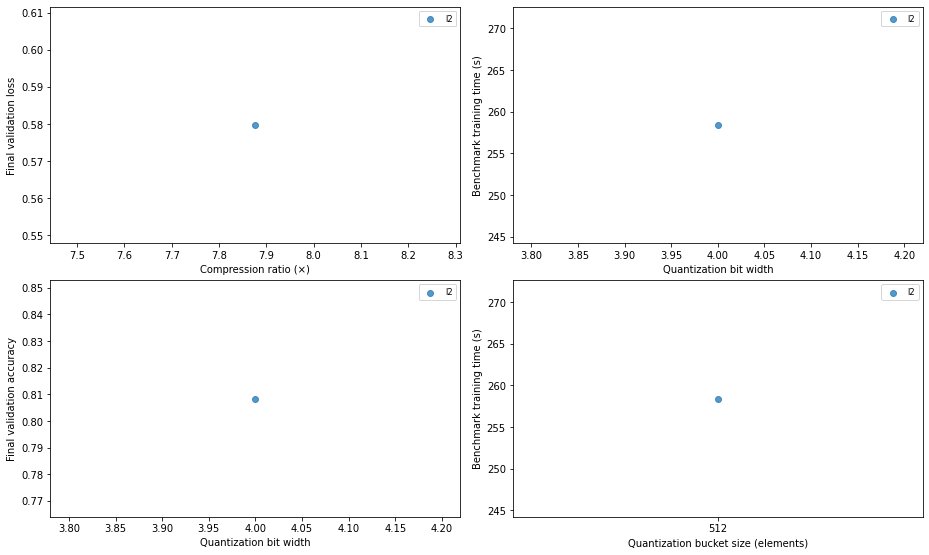

In [24]:
def pair_history(table, index):
    metrics = ["train_loss", "validation_loss", "validation_accuracy"]
    if table.empty:
        return table
    results = []
    join_keys = [index, "samples_processed"] if index == "step" else [index, "step", "samples_processed"]
    available_metrics = [key for key in metrics if table[key].notna().any()]
    if not available_metrics:
        return table.iloc[0:0]
    for record, method, references in matched:
        data = select(table, "experiment_id", record["experiment_id"])
        refs = table.loc[table["experiment_id"].isin(r["experiment_id"] for r in references)]
        if data.empty or refs.empty:
            continue
        means = refs.groupby(join_keys, as_index=False)[available_metrics].mean()
        paired = data.merge(means, on=join_keys, suffixes=("", "_baseline"))
        paired["label"] = paired["label"] + " vs " + method
        paired["baseline_method"] = method
        for metric in available_metrics:
            paired[f"delta_{metric}"] = paired[metric] - paired[f"{metric}_baseline"]
        results.append(paired)
    return pd.concat(results, ignore_index=True) if results else table.iloc[0:0]


epoch_differences = pair_history(epoch_history, "epoch")
step_differences = pair_history(step_history, "step")
for mode in ("benchmark", "diagnostic"):
    if select(epoch_differences, "mode", mode).empty:
        continue
    display(f"{mode.title()} loss and accuracy deltas")
    histories(select(epoch_differences, "mode", mode), "epoch", "Matched epoch", [
        ("delta_train_loss", "Training loss difference"),
        ("delta_validation_loss", "Validation loss difference"),
        ("delta_validation_accuracy", "Validation accuracy difference"),
    ])
    histories(select(step_differences, "mode", mode), "step", "Matched optimizer step", [
        ("delta_train_loss", "Training loss difference"),
    ])

measured = observations(select(epoch_differences, "mode", "diagnostic"), "aggregated_mse")
if not measured.empty:
    matched_final = measured.sort_values("epoch").groupby(
        ["experiment_id", "baseline_method"], sort=False
    ).tail(1)
    scatter_specs = [
        ("aggregated_mse", "Aggregated MSE", "delta_train_loss", "Training loss difference"),
        ("aggregated_mse", "Aggregated MSE", "delta_validation_loss", "Validation loss difference"),
    ]
    scatters(matched_final, scatter_specs, group="baseline_method")
    correlations = []
    for method, runs in matched_final.groupby("baseline_method", sort=False):
        for x, _, y, y_label in scatter_specs:
            values = observations(runs, x, y)
            if len(values) >= 3 and values[x].nunique() > 1 and values[y].nunique() > 1:
                x_values, y_values = numeric(values[x]), numeric(values[y])
                correlations.append({
                    "baseline": method, "outcome": y_label, "paired_runs": len(values),
                    "Pearson r": np.corrcoef(x_values, y_values)[0, 1],
                    "Spearman rho": np.corrcoef(
                        values[x].rank().to_numpy(), values[y].rank().to_numpy()
                    )[0, 1],
                })
    if correlations:
        display(pd.DataFrame(correlations))

scatters(qsgd_diagnostics, [
    ("aggregated_rmse", "Aggregated RMSE", "final_validation_accuracy", "Final validation accuracy"),
    (
        "quantization_bucket_size", "Quantization bucket size (elements)", "aggregated_mse",
        "Aggregated gradient MSE",
    ),
], group="normalization")
scatters(select(bench_summary, "compression", "qsgd"), [
    ("compression_ratio", "Compression ratio (×)", "final_validation_loss", "Final validation loss"),
    ("compression_ratio", "Compression ratio (×)", "time_to_target", "Elapsed time to target (s)"),
    ("quantization_bits", "Quantization bit width", "training_runtime", "Benchmark training time (s)"),
    ("quantization_bits", "Quantization bit width", "final_validation_accuracy", "Final validation accuracy"),
    (
        "quantization_bucket_size", "Quantization bucket size (elements)", "training_runtime",
        "Benchmark training time (s)",
    ),
], group="normalization")

## 9. Summary tables

The first table has one row per recorded experiment. Runtime comparisons use the median of eligible benchmark baselines with identical controls and repetition index. The second table shows mean and sample standard deviation for repeated conditions across seeds and repetition indices. Runs that stopped early or did not reach a convergence target remain in the results.

In [25]:
summary_table = summary.drop(columns=["trial_group"], errors="ignore").copy()
if not pairs.empty:
    for method in BASELINES:
        by_id = select(pairs, "baseline_method", method).set_index("experiment_id")
        for metric in ("speedup", "runtime_reduction_percent"):
            summary_table[f"{metric}_vs_{method}"] = summary_table["experiment_id"].map(by_id[metric])

if not summary_table.empty:
    display(summary_table)
    if SUMMARY_CSV is not None:
        export = Path(SUMMARY_CSV)
        export.parent.mkdir(parents=True, exist_ok=True)
        summary_table.to_csv(export, index=False)
        print(f"Exported {len(summary_table)} runs to {export}.")

if not succeeded.empty:
    repeated = []
    for _, trials in succeeded.groupby("trial_group", sort=False):
        if len(trials) < 2:
            continue
        row = trials.iloc[0]
        statistics = {
            "method": row["synchronization"],
            "mode": row["mode"],
            "normalization": row["normalization"],
            "bits": row["quantization_bits"],
            "bucket": row["quantization_bucket_size"],
            "encoding": row["encoding"],
            "gpu_count": row["num_gpus"],
            "scaling": row["batch_scaling"],
            "run_ids": ", ".join(trials["experiment_id"].astype(str)),
            "runs": len(trials),
        }
        for metric in (
            "training_runtime", "samples_per_second", "final_validation_loss",
            "final_validation_accuracy", "final_test_accuracy", "time_to_target",
        ):
            values = trials[metric].dropna()
            statistics[f"{metric}_n"] = len(values)
            statistics[f"{metric}_mean"] = values.mean() if len(values) else None
            statistics[f"{metric}_std"] = values.std(ddof=1) if len(values) > 1 else None
        repeated.append(statistics)
    if repeated:
        display(pd.DataFrame(repeated))

,experiment_id,label,status,stop_reason,error,mode,synchronization,compression,normalization,quantization_bits,...,aggregated_max_error,aggregated_mae,target_reached,time_to_target,epoch_to_target,step_to_target,global_batches_to_target,synchronization_rounds_to_target,collective_calls_to_target,communication_bytes_to_target
0,9ab7da8dbcff415b88d6315de309494e,QSGD l2 4-bit / 512 / packed · e309494e,completed,epoch_budget,None,benchmark,compressed_allgather,qsgd,l2,4,...,None,None,None,None,None,None,None,None,None,None
